<a href="https://colab.research.google.com/github/Z-the-original/Qiskit-implementation-of-BB84/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install qiskit[visualization] qiskit-ibm-runtime qiskit-aer qiskit_qasm3_import
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator


Alice bits:            [1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0]
Bob measured bits:     [1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1]
Alice bases :          [0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0]
Bob bases   :          [0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1]
Final selected key:    [1, 1, 0, 1, 1, 0, 1, 0]
Is sifted key correct: True


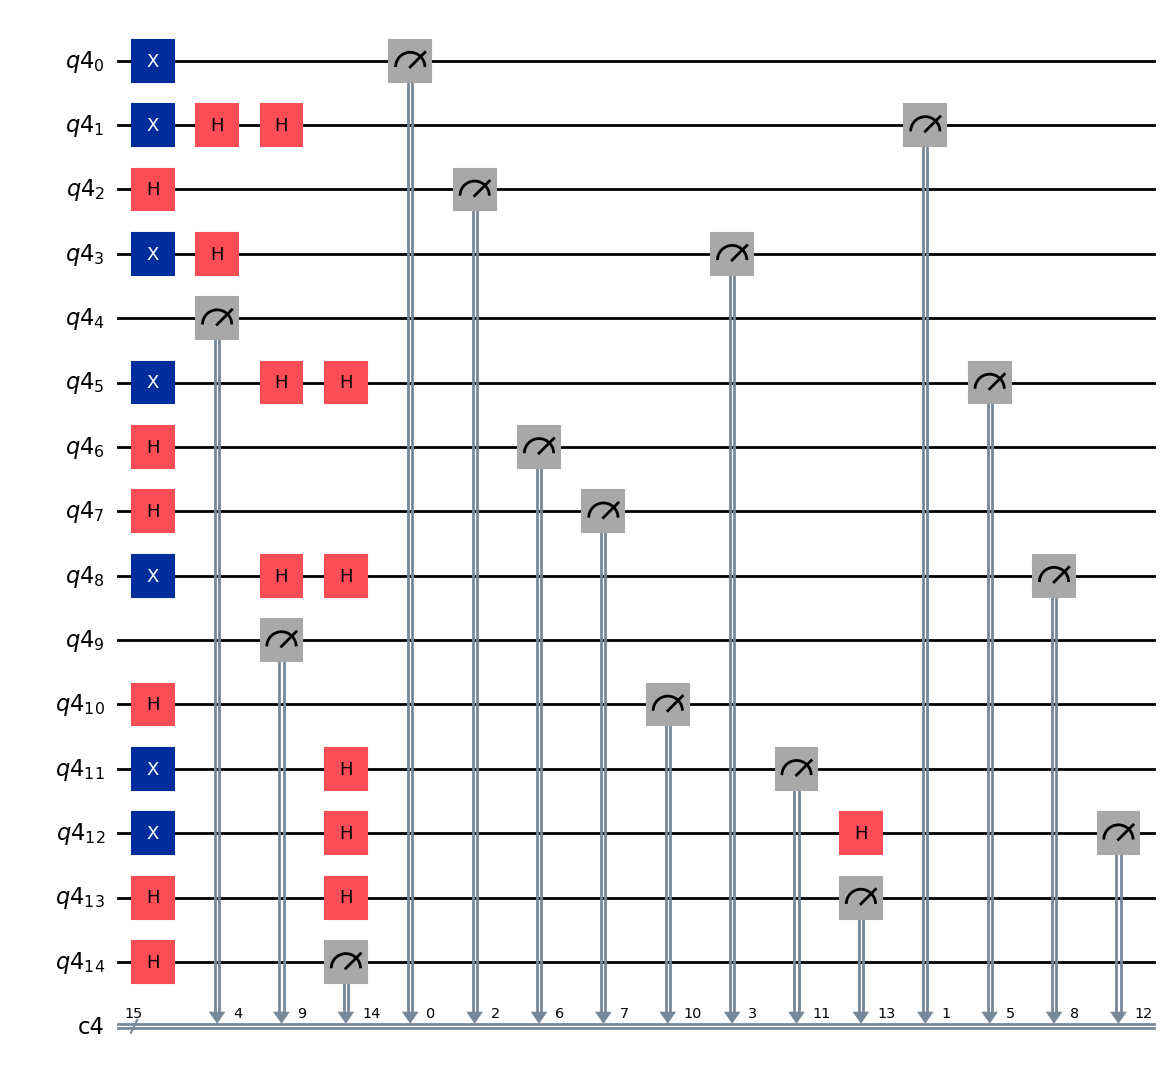

In [7]:
import random

def validate(n, bases_a,bases_b,bits_list_a,bits_list_b):
  """This function checks if our code works"""
  for i in range(n):

    if bases_a[i] == bases_b[i]:
      if bits_list_a[i] != bits_list_b[i]:
        return False
  return True



def generate_bit_or_basses_list(n):
  l = []
  for i in range(n):
    l.append(random.randint(0,1))
  return l



def get_sifted_key(n, bases_a,bases_b,bits_list):
  ''' to be used after alice and bob will make the bases they used public
  practicaly, this means that we can compare the bases strings
  and eliminate unmatching instances on both sides to get a sifted key'''

  s_key = []
  for i in range(n):
    if bases_a[i] == bases_b[i]:
      s_key.append(bits_list[i])
  return s_key

qubit_number = 15 # not a hard code, may be replcd with input statement

alice_bits = generate_bit_or_basses_list(qubit_number)
alice_bases = generate_bit_or_basses_list(qubit_number)


bob_bases = generate_bit_or_basses_list(qubit_number)

qr = QuantumRegister(qubit_number)
cr = ClassicalRegister(qubit_number)  # same number of classical bits as qubits

bb84_circuit = QuantumCircuit(qr,cr)

# here we prepare alices side
for i in range(qubit_number):
  if alice_bits[i] == 1: # turn our initial zero into one, so our qubits hold alices bits
    bb84_circuit.x(qr[i])

  if alice_bases[i] == 1: # if alice bases is 1, we encode in new basis
    bb84_circuit.h(qr[i])
# now alice sends her qubits to bob


for i in range(qubit_number):
     '''if bob's bases is one for ith position
     he measures in new basis.
     the new basis measurement means measuring after applying a
     hadamard'''

     if bob_bases[i] == 1:
       bb84_circuit.h(qr[i])
     bb84_circuit.measure(qr[i], cr[i])




# in this part we run the circuit which represents the protocll
simulator = AerSimulator()
job = simulator.run(bb84_circuit, shots=1)
results = job.result()
output = (list(results.get_counts().keys())[0])


bob_bits = [int(i) for i in output][::-1]

sifted_key = get_sifted_key(qubit_number, alice_bases, bob_bases, bits_list=alice_bits)


'''This sifted key is known by both Alice and Bob'''

print("Alice bits:           ", alice_bits)
print("Bob measured bits:    ", bob_bits)
print("Alice bases :         ", alice_bases)
print("Bob bases   :         ", bob_bases)
print('Final selected key:   ',sifted_key)


print('Is sifted key correct:',validate(qubit_number,alice_bases,bob_bases,alice_bits,bob_bits))

bb84_circuit.draw('mpl')